# micrograd

Following Andrej Karpathy's lecture [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0&list=PLXYLzZ3XzIbi4lL43O6fIU_ojuZwBO6vi).

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

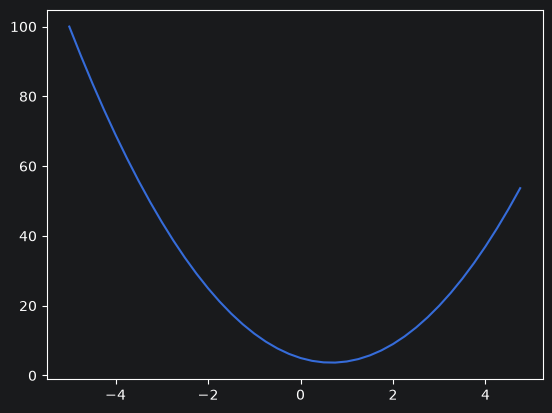

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out = Value(self.data + val.data, (self, val), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            val.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __radd__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return self + val

    def __sub__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out = Value(self.data - val.data, (self, val), '-')

        def _backward():
            self.grad += 1.0 * out.grad
            val.grad -= 1.0 * out.grad

        out._backward = _backward
        return out


    def __rsub__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return val - self

    def __mul__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        out =  Value(self.data * val.data, (self, val), '*')

        def _backward():
            self.grad += val.data * out.grad
            val.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return self * val

    def __truediv__(self, val):
        out = val if isinstance(val, Value) else Value(val)

        def _backward():
            self.grad = 1.0 / val.data * out.grad
            val.grad = - self.data / val.data**2.0 * out.grad
        return Value(self.data / val.data, (self, val), '/')

    def __rtruediv__(self, val):
        val = val if isinstance(val, Value) else Value(val)
        return val/self

    def tanh(self):
        out =  Value( np.tanh(self.data), (self, ), 'tanh')
        def _backward():
            self.grad += (1.0 - out.data**2.0) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        for val in topo:
            val.grad = 0.0
        self.grad = 1.0
        for val in reversed(topo):
            val._backward()
        print(f"{topo}")


In [6]:
from graphviz import Digraph
def trace(root):
    nodes = set()
    edges = set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = f"{{ {n.label} | data: {n.data:.4f} | grad: {n.grad:.4f} }}", shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [7]:
h = 0.0001

a=Value(2.0, label='a')
b=Value(-3.0, label='b')
c=Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
L1 = L.data

# a=Value(2.0 + h, label='a')
# b=Value(-3.0, label='b')
# c=Value(10.0, label='c')
# e = a*b; e.label = 'e'
# d = e + c; d.label = 'd'
# f = Value(-2.0, label='f')
# L = d*f; L.label = 'L'
# L2 = L.data
# print((L2-L1)/h)

L.grad = 1.0
f.grad = 4.0
d.grad = -2.0


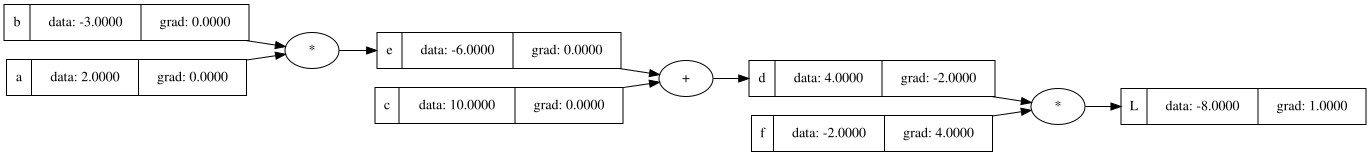

In [8]:
draw_dot(L)

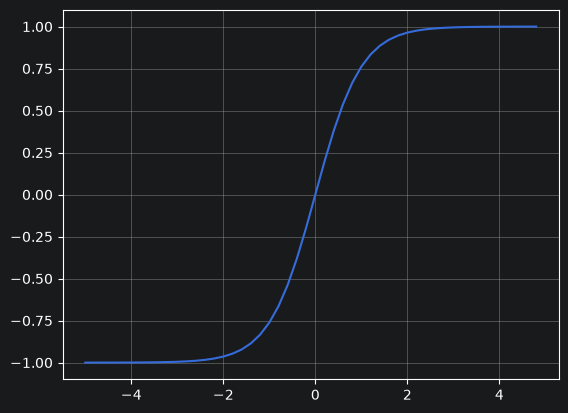

In [9]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

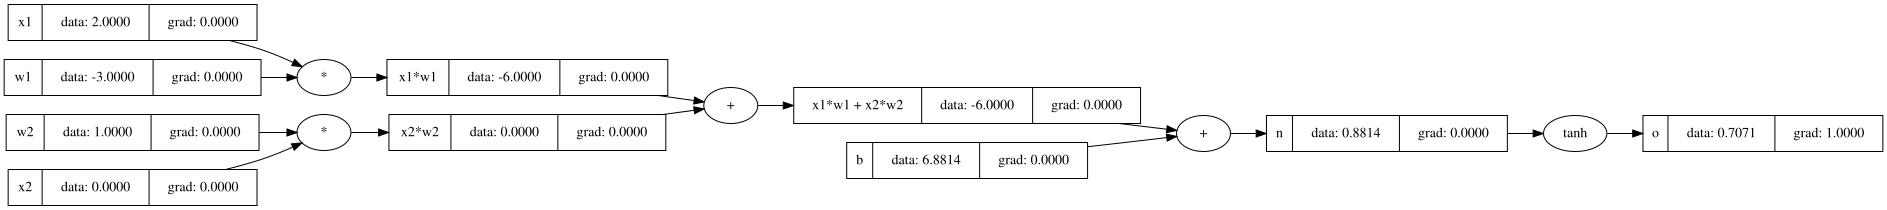

In [10]:
# inputs x1, x2
x1 = Value(2.0, label ='x1')
x2 = Value(0.0, label ='x2')
# weights w1, w2
w1 = Value(-3.0, label ='w1')
w2 = Value(1.0, label ='w2')
# bias of the neuron
b = Value (6.8813735870195432, label ='b')
# x1*w1 + x2*w1 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.grad = 1.0
draw_dot(o)

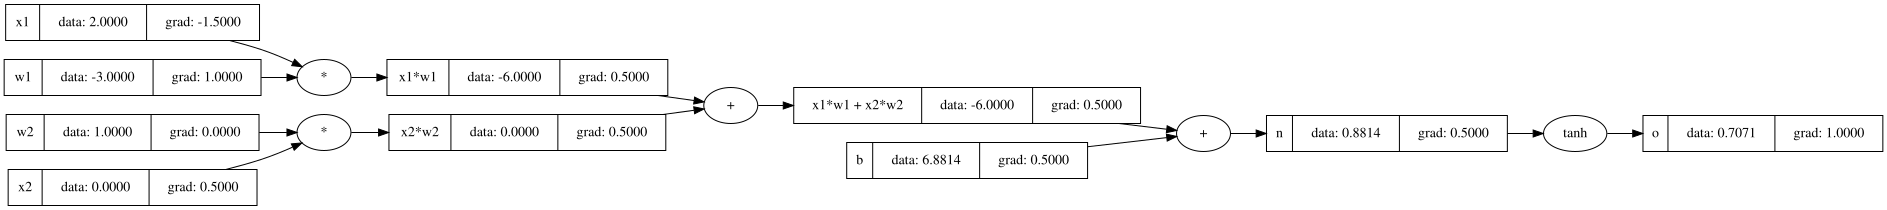

In [11]:
n.grad = 0.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
draw_dot(o)

[Value(data=6.881373587019543), Value(data=2.0), Value(data=-3.0), Value(data=-6.0), Value(data=1.0), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.8813735870195432), Value(data=0.7071067811865476)]


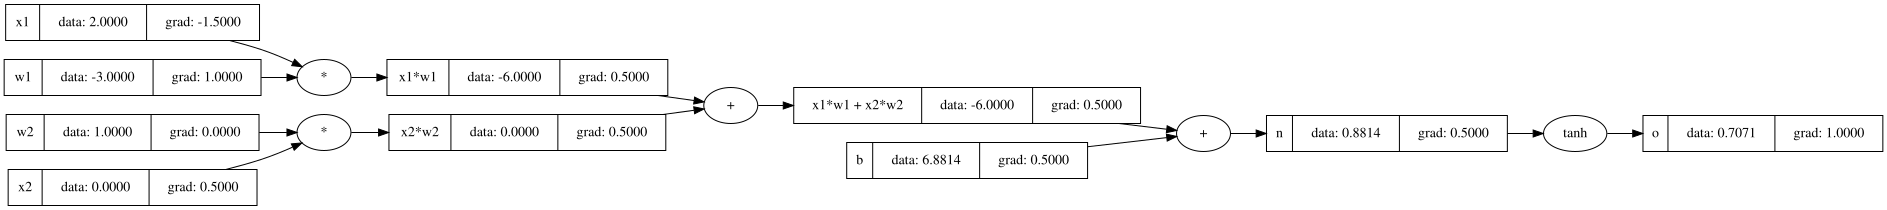

In [15]:
# topo = []
# visited = set()
#
# def build_topo(v):
#     if v not in visited:
#         visited.add(v)
#         for child in v._prev:
#             build_topo(child)
#         topo.append(v)
#
# build_topo(o)
# topo

o.backward()
draw_dot(o)